In [1]:
!pip install ipywidgets==8.1.9

In [1]:
import numpy as np
import pandas as pd

import tensorflow as tf
import keras
from keras import layers
from numpy import array

# Para el dataset
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ipywidgets import interact, FloatSlider, VBox, HBox, Button, Output, IntSlider
import time
from IPython.display import display, clear_output

from keras import regularizers

I0000 00:00:1792086726.794797   54213 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792086727.050308   54213 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792086728.400911   54213 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [5]:
from pathlib import Path
import json

import seaborn as sns

# Análisis de DataSet

Apertura de los datasets reducidos disponibles en `data_redux/`.

In [6]:

DATA_DIR = Path("data_redux")

def abrir_dataset(nombre_archivo):
    """Abre y retorna el contenido JSON de un archivo en data_redux."""
    ruta = DATA_DIR / nombre_archivo
    with ruta.open(encoding="utf-8") as archivo:
        return json.load(archivo)

#hojas_de_ruta = abrir_dataset("hojaDeRuta_reducido.json")
#rastreo_satelital = abrir_dataset("rastreoSatelital_reducido.json")
observaciones_viales = abrir_dataset("observacionesSegmentosViales_redux2.json")

#print("Hojas de ruta cargadas:", len(hojas_de_ruta))
#print("Registros de rastreo satelital:", len(rastreo_satelital))
print("Observaciones de segmentos viales:", len(observaciones_viales))


JSONDecodeError: Extra data: line 1 column 179 (char 178)

In [7]:
DATA_DIR = Path("data_redux")

def abrir_dataset(nombre_archivo):
    """Abre y retorna el contenido JSON de un archivo en data_redux."""
    ruta = DATA_DIR / nombre_archivo
    with ruta.open(encoding="utf-8") as archivo:
        contenido = archivo.read().strip().rstrip(",")
        # Si no empieza con '[', lo envolvemos para formar una lista JSON válida
        if not contenido.startswith("["):
            contenido = f"[{contenido}]"
        return json.loads(contenido)

observaciones_viales = abrir_dataset("observacionesSegmentosViales_redux2.json")
print("Observaciones de segmentos viales:", len(observaciones_viales))

Observaciones de segmentos viales: 243


In [8]:
# Inspección rápida de estructura y muestra (sin volcar geometrías grandes)
datasets = {
    #"hojas_de_ruta": hojas_de_ruta,
    #"rastreo_satelital": rastreo_satelital,
    "observaciones_viales": observaciones_viales,
}

for nombre, datos in datasets.items():
    print(f"\n=== {nombre} ===")
    if isinstance(datos, list) and datos and isinstance(datos[0], dict):
        print("Claves:", list(datos[0].keys()))
        muestra = {}
        for clave, valor in datos[0].items():
            if isinstance(valor, (list, dict)) and len(json.dumps(valor)) > 500:
                muestra[clave] = f"<{type(valor).__name__} ({len(valor)} elementos)>"
            else:
                muestra[clave] = valor
        print("Muestra:", json.dumps(muestra, ensure_ascii=False, indent=2))
    else:
        print(type(datos))



=== observaciones_viales ===
Claves: ['nodo_origen', 'nodo_destino', 'franja_horaria', 'tiempo_real', 'fecha', 'flotaID']
Muestra: {
  "nodo_origen": 13698144984,
  "nodo_destino": 5864322509,
  "franja_horaria": "Viernes_19_20",
  "tiempo_real": 120.5,
  "fecha": {
    "$date": "2026-06-05T22:07:05.000Z"
  },
  "flotaID": "VEH_e3d5866f0c"
}


In [9]:
data = pd.DataFrame(datasets)

data.head()
data.describe()
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 1 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   observaciones_viales  243 non-null    object
dtypes: object(1)
memory usage: 2.0+ KB


In [11]:
print(data.columns)

Index(['observaciones_viales'], dtype='str')


In [12]:
sns.set_theme(style="whitegrid")

# 1. Desempaquetar los diccionarios anidados
df = pd.json_normalize(data['observaciones_viales'])

# 2. Convertir la fecha a datetime
df['fecha_dt'] = pd.to_datetime(df['fecha.$date'])

# 3. Crear columnas auxiliares
df['dia_fecha'] = df['fecha_dt'].dt.date         # Ejemplo: 2026-06-05
df['hora'] = df['fecha_dt'].dt.hour              # Ejemplo: 22
df['nombre_dia'] = df['fecha_dt'].dt.day_name()  # Ejemplo: Friday

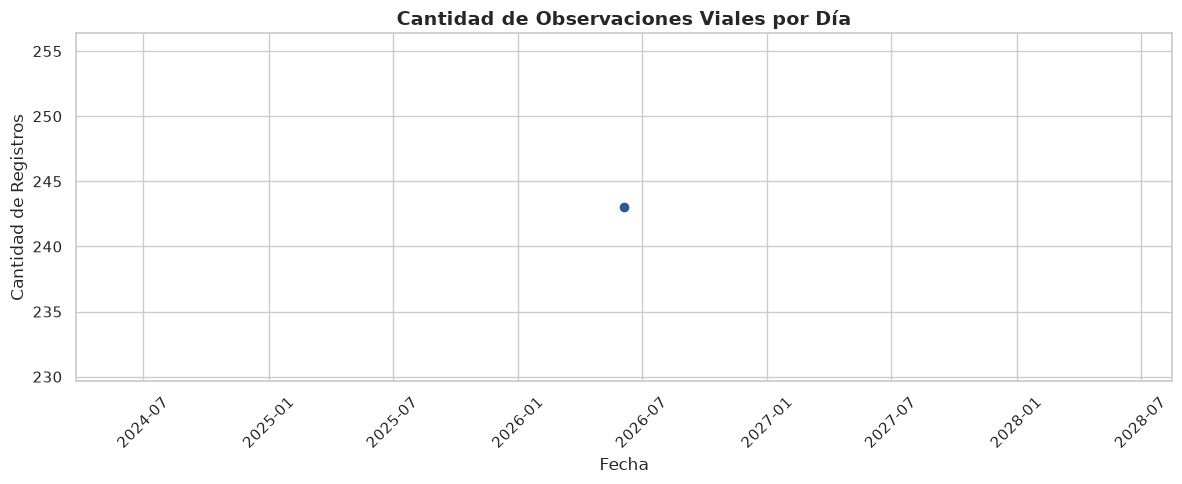

In [13]:
# Opción: Cantidad de observaciones por día
obs_por_dia = df.groupby('dia_fecha').size()

plt.figure(figsize=(12, 5))
obs_por_dia.plot(kind='line', marker='o', linewidth=2, color='#2b5c8f')
plt.title('Cantidad de Observaciones Viales por Día', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Cantidad de Registros', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

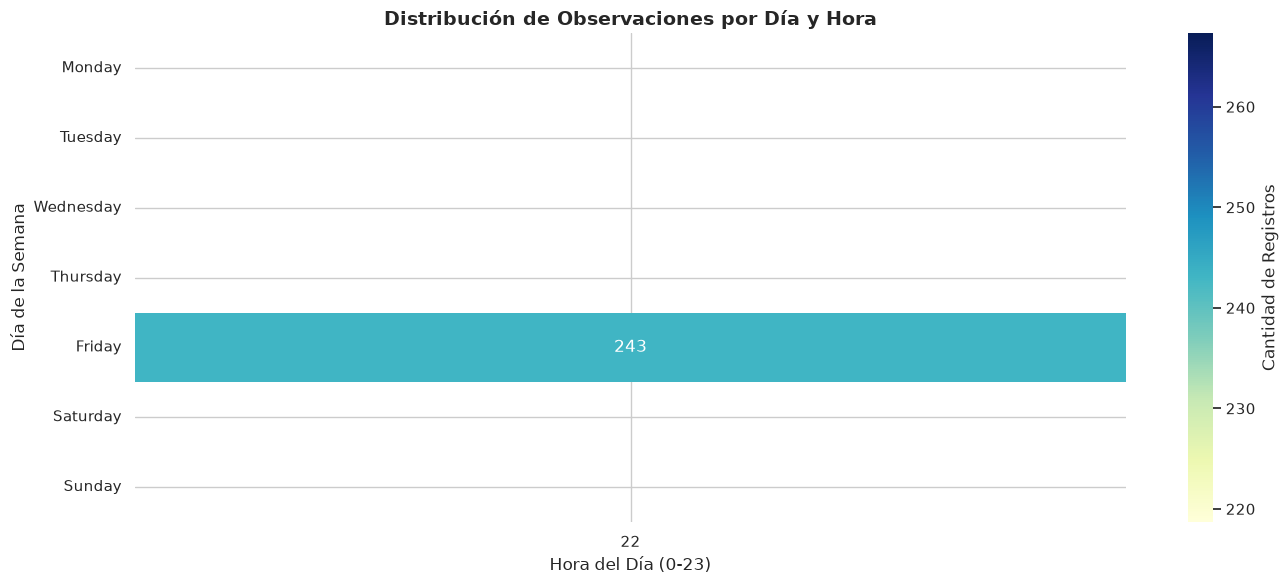

In [19]:
# Ordenar días de la semana
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Pivote para el Mapa de Calor (conteo de registros por día y hora)
pivot_tabla = df.pivot_table(
    index='nombre_dia', 
    columns='hora', 
    values='tiempo_real', 
    aggfunc='count'
).reindex(dias_orden)

plt.figure(figsize=(14, 6))
sns.heatmap(pivot_tabla, cmap='YlGnBu', annot=True, fmt='.0f', cbar_kws={'label': 'Cantidad de Registros'})
plt.title('Distribución de Observaciones por Día y Hora', fontsize=14, fontweight='bold')
plt.xlabel('Hora del Día (0-23)', fontsize=12)
plt.ylabel('Día de la Semana', fontsize=12)
plt.tight_layout()
plt.show()

In [21]:
sns.set_theme(style="whitegrid")

path = '/home/jerexio/Universidad/Lab de IA/temp-lab-ia/test_temp/data_redux/observacionesSegmentosViales_redux2.json'

# 1. Leer el archivo e imponer formato de lista JSON []
with open(path, 'r', encoding='utf-8') as f:
    contenido = f.read().strip().rstrip(",")
    if not contenido.startswith("["):
        contenido = f"[{contenido}]"

# Cargar el JSON procesado en el DataFrame
df = pd.DataFrame(json.loads(contenido))

# 2. Convertir la fecha anidada a datetime
df['fecha_dt'] = pd.to_datetime(df['fecha'].apply(lambda x: x['$date'] if isinstance(x, dict) else x))

# 3. Crear columnas auxiliares
df['dia'] = df['fecha_dt'].dt.date
df['hora'] = df['fecha_dt'].dt.hour
df['nombre_dia'] = df['fecha_dt'].dt.day_name()

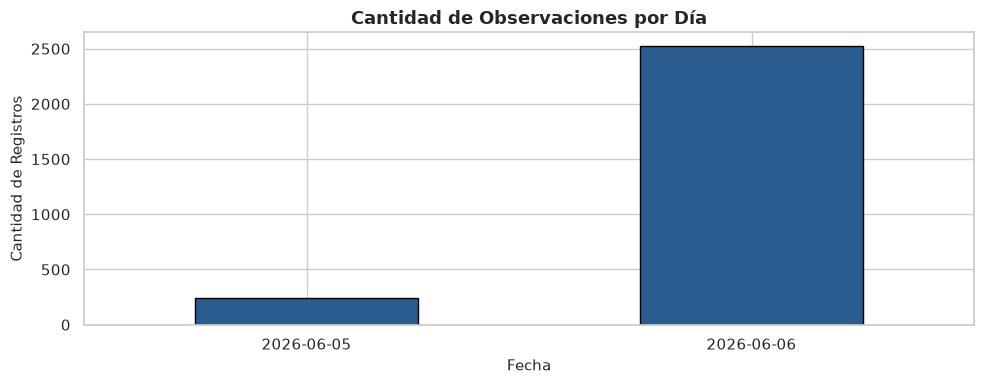

In [22]:
plt.figure(figsize=(10, 4))
df.groupby('dia').size().plot(kind='bar', color='#2b5c8f', edgecolor='black')
plt.title('Cantidad de Observaciones por Día', fontsize=13, fontweight='bold')
plt.xlabel('Fecha', fontsize=11)
plt.ylabel('Cantidad de Registros', fontsize=11)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

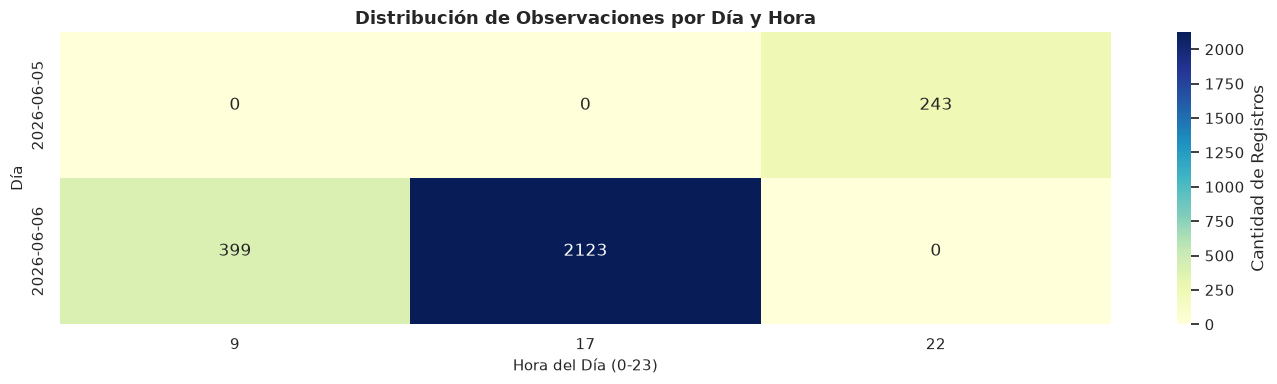

In [23]:
pivot_dia_hora = df.pivot_table(
    index='dia', 
    columns='hora', 
    values='tiempo_real', 
    aggfunc='count',
    fill_value=0
)

plt.figure(figsize=(14, 4))
sns.heatmap(pivot_dia_hora, cmap='YlGnBu', annot=True, fmt='d', cbar_kws={'label': 'Cantidad de Registros'})
plt.title('Distribución de Observaciones por Día y Hora', fontsize=13, fontweight='bold')
plt.xlabel('Hora del Día (0-23)', fontsize=11)
plt.ylabel('Día', fontsize=11)
plt.tight_layout()
plt.show()